# Modeling approach brainstorming

## Goal

> Explain what drives the seasonal variation in discharge at Zachariæ Isstrøm.

Air temperature and runoff rise and fall with the calendar almost exactly: every summer is warm and wet, every winter cold and dry. So do the other candidate processes, such as melt, mélange break-up, sea ice and fjord stratification. Each has its own summer high or low. As a result, every candidate lines up with the average seasonal cycle of discharge about equally well, because each mostly tells us the same thing: what time of year it is. Matching the average discharge seasonal cycle therefore can't, on its own, tell us which process drives it.

What can is *year-to-year variation*. Some summers are warmer than others, some have more runoff, and some see earlier mélange break-up. If a driver matters, then *the months or years when it was unusual should be the months or years when discharge was unusual too*.

This notebook sets up that test in four steps:

1. Look at the target (glacier-wide discharge) and two candidate drivers (runoff and air temperature).
2. Remove the long-term trend and the usual annual cycle, the **two detrending steps**, leaving the "unusual" part.
3. Set up leave-one-year-out cross-validation (CV).
4. Compare a minimal XGBoost model with a baseline, then list next steps.

It runs in under a minute on a laptop:

```bash
export AWS_PROFILE=kopah          # or AWS_ACCESS_KEY_ID / AWS_SECRET_ACCESS_KEY
pixi run -e local jupyter lab     # then open this notebook
```

In [1]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt

from local_model import load_monthly, slow_component, TARGET_COL, RUNOFF, AIRT

%matplotlib inline
INK, GRAY, MUTED = "#0b0b0b", "#8a8985", "#52514e"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False,
})

## 1. The target and two candidate drivers

The data are monthly glacier-wide values:
- discharge in gigatonnes of ice per year (Gt/yr);
- basin-averaged meltwater runoff in millimeters of water equivalent per day (mmWE/day);
- air temperature in °C.

The analysis period starts in July 2008, when the air temperature record begins.

In [2]:
df = load_monthly()                                   # monthly means of zach_non_spatial.parquet (cached in data/)
START = "2008-07-01"
data = pd.DataFrame({
    "discharge": df[TARGET_COL],
    "runoff": df[RUNOFF],
    "air_temp": df[AIRT],
}).loc[START:"2025-12-01"]
print(f"{len(data)} months, {data.index.min():%Y-%m} to {data.index.max():%Y-%m}")
data.describe().round(2)

210 months, 2008-07 to 2025-12


,discharge,runoff,air_temp
count,210.00,210.00,210.00
mean,14.81,0.99,-17.12
std,1.67,2.33,10.85
min,11.39,0.00,-32.29
25%,13.22,0.00,-26.50
50%,15.40,0.00,-20.09
75%,16.28,0.36,-5.65
max,16.99,11.60,1.66


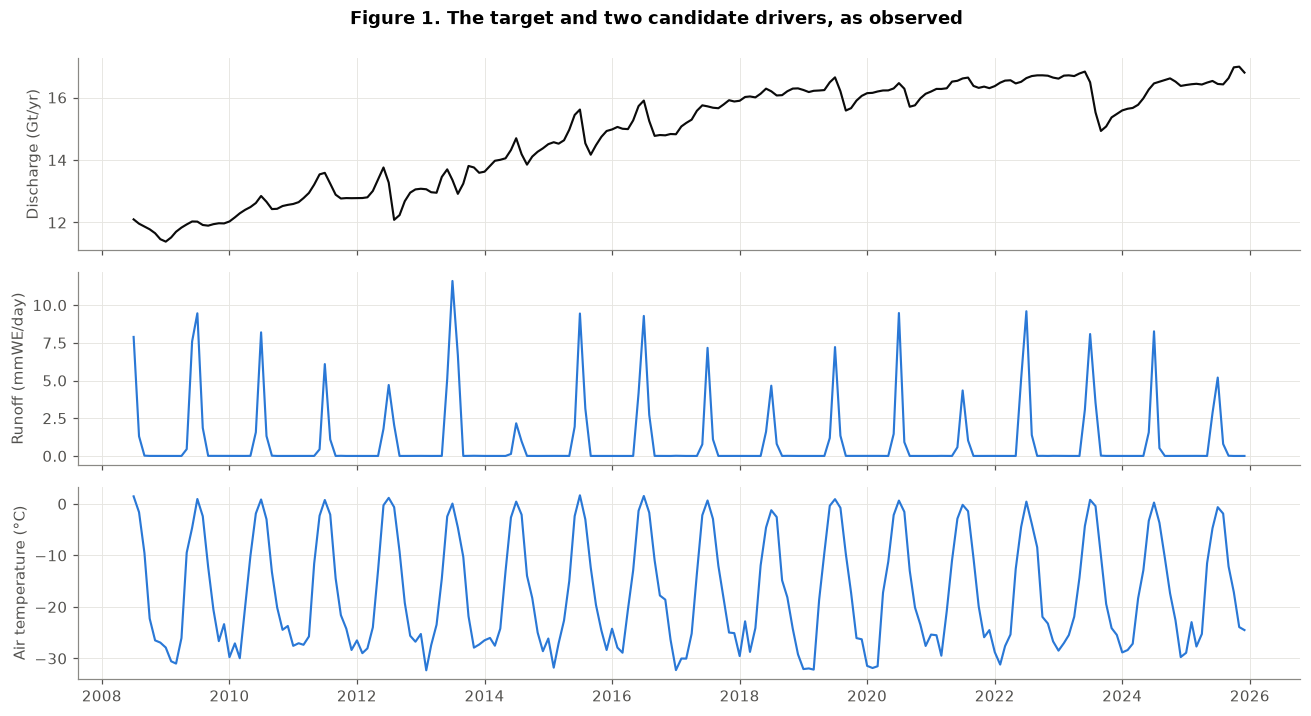

runoff   : calendar month explains 82% of its variation; long-term change 2009–2024 -0.18 mmWE/day, vs. a seasonal range of 7.4 mmWE/day
air_temp : calendar month explains 97% of its variation; long-term change 2009–2024 +0.45 °C, vs. a seasonal range of 29.2 °C


In [3]:
panels = [("discharge", "Discharge (Gt/yr)", INK), ("runoff", "Runoff (mmWE/day)", BLUE),
          ("air_temp", "Air temperature (°C)", BLUE)]
fig, axes = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True)
for ax, (col, label, color) in zip(axes, panels):
    ax.plot(data.index, data[col], color=color)
    ax.set_ylabel(label)
fig.suptitle("Figure 1. The target and two candidate drivers, as observed", fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

def calendar_share(s):
    # Fraction of a series' month-to-month variation explained by the calendar month alone
    s = s.dropna()
    return 1 - ((s - s.groupby(s.index.month).transform("mean")) ** 2).sum() / ((s - s.mean()) ** 2).sum()

for col, unit in [("runoff", "mmWE/day"), ("air_temp", "°C")]:
    yearly = data[col].groupby(data.index.year).mean().loc[2009:2024]
    change = np.polyfit(yearly.index, yearly.values, 1)[0] * (2024 - 2009)      # straight-line change over 2009–2024
    monthly = data[col].groupby(data.index.month).mean()
    print(f"{col:9s}: calendar month explains {calendar_share(data[col]):.0%} of its variation; "
          f"long-term change 2009–2024 {change:+.2f} {unit}, vs. a seasonal range of {monthly.max() - monthly.min():.1f} {unit}")

Two features stand out:

- **Discharge is dominated by a long-term rise** (about 12 → 17 Gt/yr), with a small seasonal wiggle on top.
- **Runoff and air temperature are dominated by the annual cycle**, with no meaningful long-term trend. The calendar
  month alone explains about 82% and 97% of their variation.

Neither the long-term rise nor the average annual cycle can identify a driver, so both get removed before any
modeling.

## 2. Two detrending steps

- **Step 1: remove the long-term trend** (discharge only). Subtract a centered 12-month running mean. What's left is the
  **seasonal anomaly**. The drivers have no long-term trend, so they skip this step.
- **Step 2: remove the usual annual cycle** (discharge and drivers). Subtract each calendar month's average, e.g. the
  average of all Julys from every July. What's left is the **departure**: how unusual that month was for its time of
  year.

The departures are what the drivers have to explain.

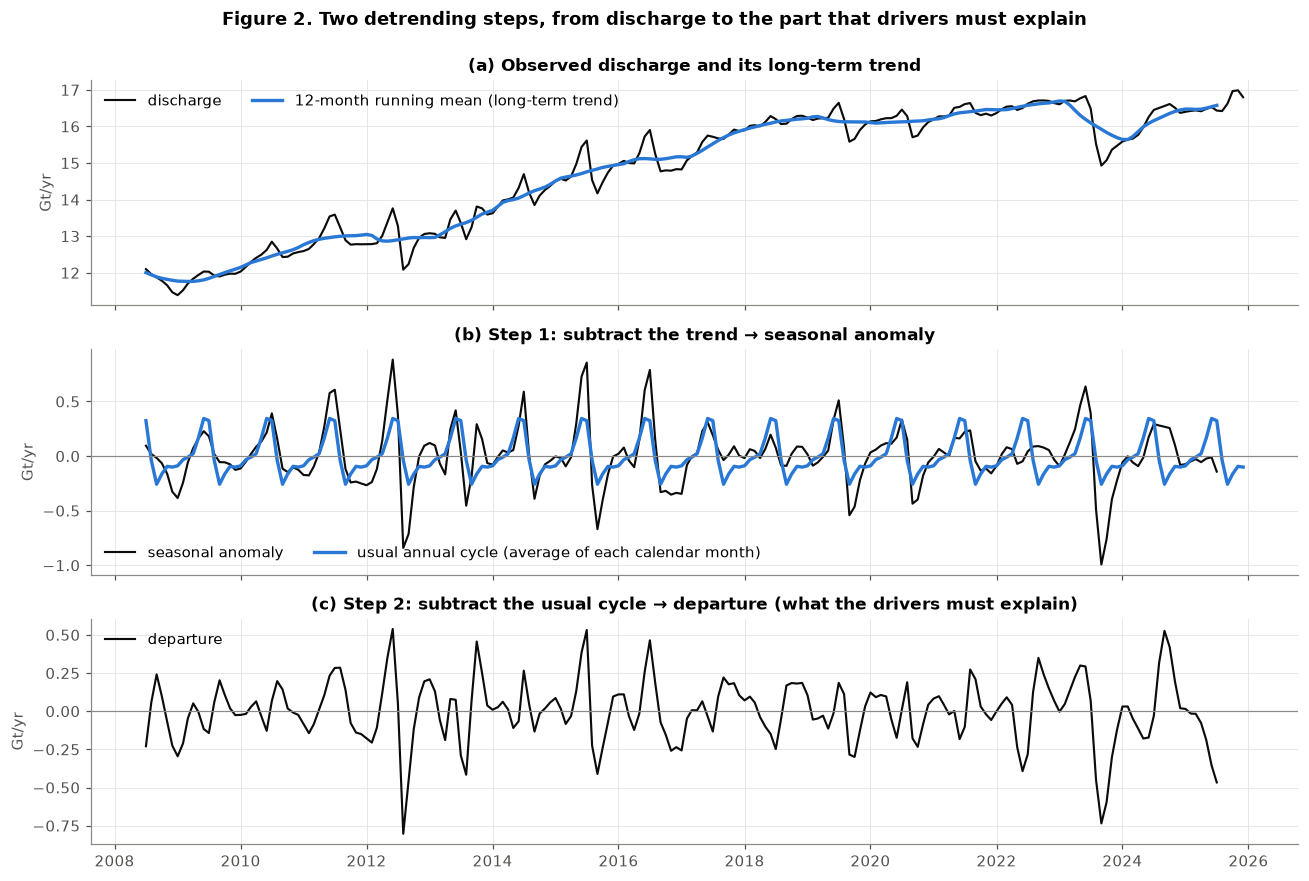

Share of discharge variance, 2008-07 to 2025-07:
  long-term trend       97.3%
  usual annual cycle     1.2%
  departures             1.5%   (std 0.20 Gt/yr)


In [4]:
def usual_cycle(s):
    # The average value for each calendar month, repeated every year
    return s.groupby(s.index.month).transform("mean")

slow = slow_component(df[TARGET_COL]).reindex(data.index)  # step 1: centered 12-month running mean
data["anomaly"] = data["discharge"] - slow                   # seasonal anomaly
data["usual"] = usual_cycle(data["anomaly"])                 # step 2: the usual annual cycle
data["departure"] = data["anomaly"] - data["usual"]          # departure from the usual cycle

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(data.index, data["discharge"], color=INK, label="discharge")
axes[0].plot(data.index, slow, color=BLUE, lw=2.2, label="12-month running mean (long-term trend)")
axes[0].set(ylabel="Gt/yr", title="(a) Observed discharge and its long-term trend")
axes[1].plot(data.index, data["anomaly"], color=INK, label="seasonal anomaly")
axes[1].plot(data.index, data["usual"], color=BLUE, lw=2.2, label="usual annual cycle (average of each calendar month)")
axes[1].set(ylabel="Gt/yr", title="(b) Step 1: subtract the trend → seasonal anomaly")
axes[2].plot(data.index, data["departure"], color=INK, label="departure")
axes[2].set(ylabel="Gt/yr", title="(c) Step 2: subtract the usual cycle → departure (what the drivers must explain)")
for ax in axes[1:]:
    ax.axhline(0, color=GRAY, lw=0.8)
axes[0].legend(loc="upper left", ncol=2)
axes[1].legend(loc="lower left", ncol=2)
axes[2].legend(loc="upper left")
fig.suptitle("Figure 2. Two detrending steps, from discharge to the part that drivers must explain",
             fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

ok = data["departure"].notna()
total = data.loc[ok, "discharge"].var()
print(f"Share of discharge variance, {data.index[ok].min():%Y-%m} to {data.index[ok].max():%Y-%m}:")
print(f"  long-term trend      {1 - data.loc[ok, 'anomaly'].var() / total:6.1%}")
print(f"  usual annual cycle   {(data.loc[ok, 'anomaly'].var() - data.loc[ok, 'departure'].var()) / total:6.1%}")
print(f"  departures           {data.loc[ok, 'departure'].var() / total:6.1%}   (std {data.loc[ok, 'departure'].std():.2f} Gt/yr)")

The departures are a small part of the total variance, but they're exactly the part that can discriminate between
drivers.

The same step 2 applied to the drivers gives their departures: warmer, colder, wetter or drier than usual for that
time of year. Figure 3 puts them side by side. The question this notebook tests is whether the bumps in the lower
two panels line up with the bumps in the top panel, in the same month or a few months earlier.

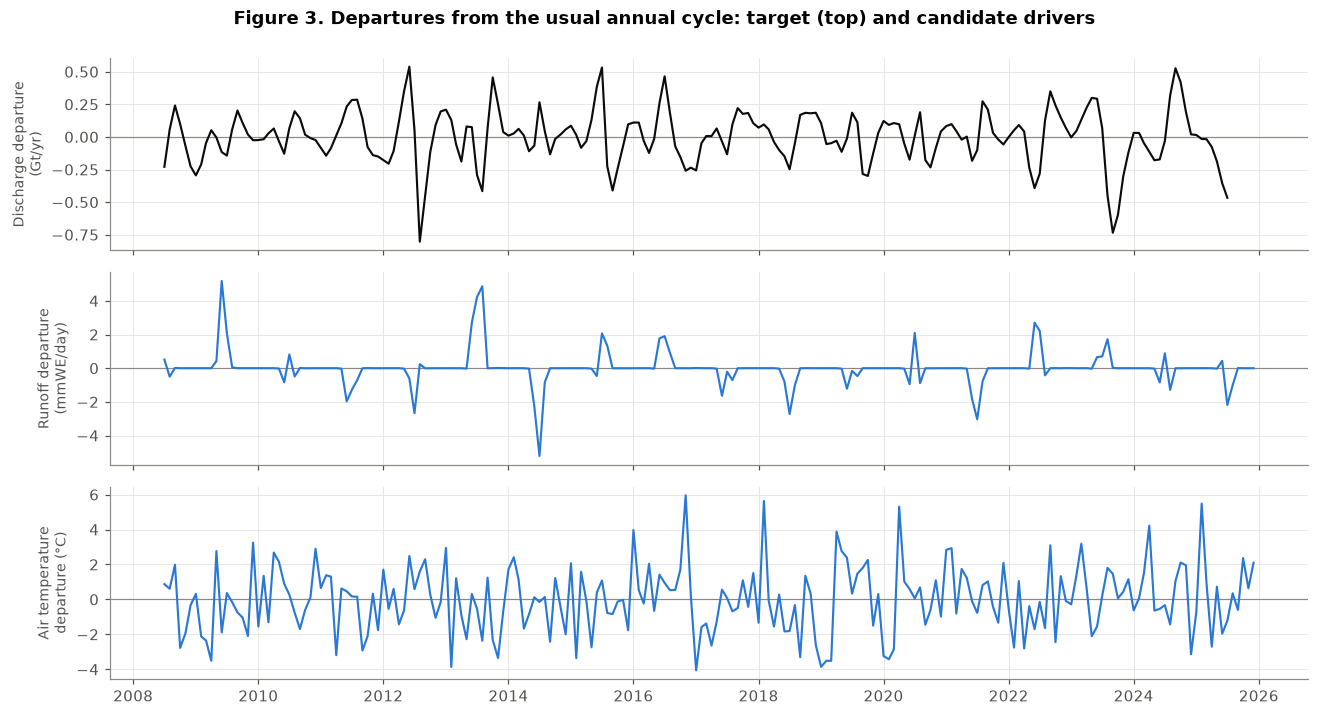

In [5]:
data["runoff_departure"] = data["runoff"] - usual_cycle(data["runoff"])
data["air_temp_departure"] = data["air_temp"] - usual_cycle(data["air_temp"])

panels = [("departure", "Discharge departure\n(Gt/yr)", INK),
          ("runoff_departure", "Runoff departure\n(mmWE/day)", BLUE),
          ("air_temp_departure", "Air temperature\ndeparture (°C)", BLUE)]
fig, axes = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True)
for ax, (col, label, color) in zip(axes, panels):
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.plot(data.index, data[col], color=color)
    ax.set_ylabel(label, fontsize=9)
fig.suptitle("Figure 3. Departures from the usual annual cycle: target (top) and candidate drivers",
             fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

## 3. How we test it: leave-one-year-out cross-validation

Each year from 2009 to 2024 takes a turn as the **held-out (test) year**. For each one:
1. Fit a fresh model on all other months, except a **6-month buffer** on each side of the held-out year.
2. Predict the held-out year.

Every month gets predicted exactly once, by a model that never saw it. The buffer matches the half-width of the
12-month running mean in step 1, so no training month's target uses discharge from the held-out year.

Two further details:
- **The usual annual cycle (step 2) is recomputed inside each fold, from the training months only**, so the held-out
  year never influences what counts as "usual."
- **No separate validation set is needed.** All model settings are fixed in advance (section 4); nothing is tuned on
  held-out data.

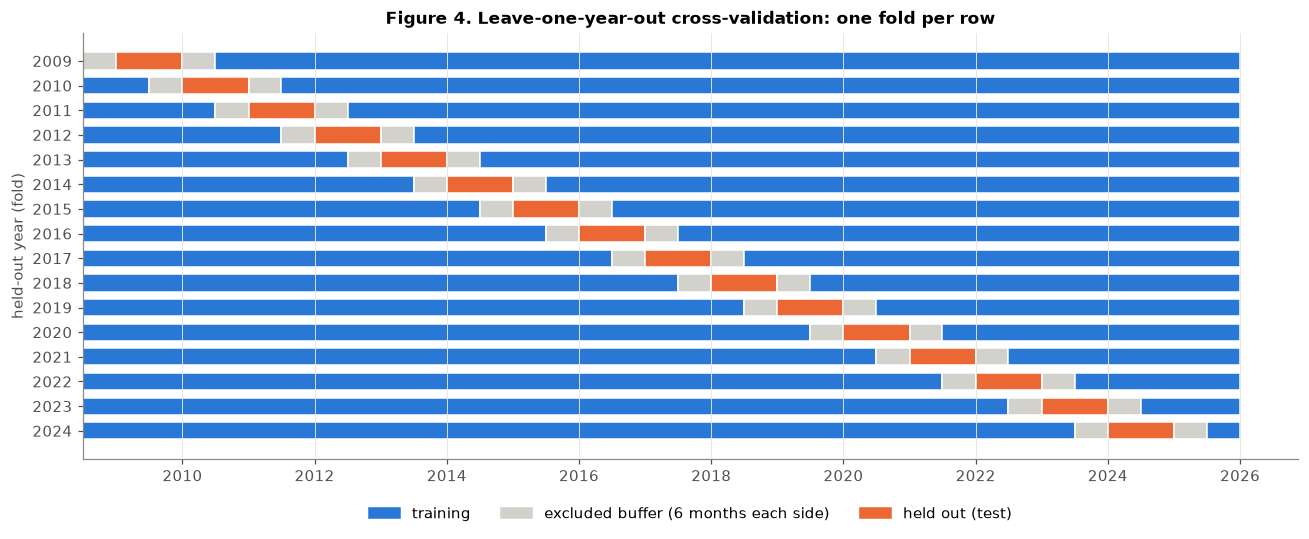

In [6]:
YEARS = range(2009, 2025)
BUFFER_MONTHS = 6

fig, ax = plt.subplots(figsize=(12, 5))
start, end = data.index.min(), data.index.max() + pd.DateOffset(months=1)
for row, year in enumerate(YEARS):
    held_start, held_end = pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year + 1}-01-01")
    buf_start = held_start - pd.DateOffset(months=BUFFER_MONTHS)
    buf_end = held_end + pd.DateOffset(months=BUFFER_MONTHS)
    for a, b, color in [(start, buf_start, BLUE), (buf_start, held_start, "#d3d1cb"), (held_start, held_end, ORANGE),
                        (held_end, buf_end, "#d3d1cb"), (buf_end, end, BLUE)]:
        a, b = max(a, start), min(b, end)
        if b > a:
            ax.barh(row, b - a, left=a, height=0.7, color=color, edgecolor="white", linewidth=1)
ax.set_yticks(range(len(YEARS)), [str(y) for y in YEARS])
ax.set_ylabel("held-out year (fold)")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, "#d3d1cb", ORANGE)]
ax.legend(handles, ["training", f"excluded buffer ({BUFFER_MONTHS} months each side)", "held out (test)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
ax.set_title("Figure 4. Leave-one-year-out cross-validation: one fold per row")
plt.tight_layout()
plt.show()

## 4. Baseline vs. a minimal XGBoost model

**Baseline: the usual annual cycle.** It predicts that every month looks like the average for its calendar month, so
its predicted *departure* is always zero. Any driver model has to beat this.

**Minimal XGBoost model.** It predicts the discharge departure from:
- the calendar month, so the response can differ by season (e.g. a warm July vs. a warm January);
- runoff and air-temperature departures in the same month and the 3 previous months (lags 0–3).

All settings are fixed in advance:

| Setting | Value | Why |
|---|---|---|
| `max_depth` | 2 | each tree combines at most two conditions (e.g. "July *and* warmer than usual") |
| learning rate `eta` | 0.05 | small, cautious steps |
| number of trees | 200 | with `eta=0.05`, enough to fit the pattern without chasing noise |
| `min_child_weight` | 5 | no rule may rest on fewer than about 5 training months |
| row/column sampling | none | keeps the result deterministic, with no dependence on a random seed |
| objective | squared error | each leaf predicts a mean |

**How the two are scored.** Over all held-out months:

> **skill = 1 − (model's total squared error ÷ baseline's total squared error)**

- Skill above 0 means the model's errors are smaller than the baseline's. For example, a skill of 0.2 means 20% less
  squared error.
- Skill of 0 means no better than the baseline; below 0 means worse.

We also count in how many of the 16 held-out years the model's error is smaller than the baseline's. That shows
whether any advantage is consistent or comes from just a few years.

In [7]:
PARAMS = dict(objective="reg:squarederror", max_depth=2, eta=0.05, min_child_weight=5)
N_TREES = 200
LAGS = range(4)

def departure_from(series, train):
    # Step 2 inside a fold: subtract the usual value for each calendar month, computed from training months only
    usual = series[train].groupby(series[train].index.month).mean()
    return series - series.index.month.map(usual).to_numpy()

def model_inputs(runoff_dep, air_temp_dep):
    X = pd.DataFrame({"month": data.index.month}, index=data.index)
    for k in LAGS:
        X[f"runoff_dep_lag{k}"] = runoff_dep.shift(k)
        X[f"air_temp_dep_lag{k}"] = air_temp_dep.shift(k)
    return X

folds = []
importance = {}                   # each fold model's importance per input, used in section 4
for year in YEARS:
    held_out = data.index.year == year
    near = (data.index >= f"{year - 1}-07-01") & (data.index < f"{year + 1}-07-01")   # held-out year ± 6 months
    train = ~near
    target = departure_from(data["anomaly"], train)
    X = model_inputs(departure_from(data["runoff"], train), departure_from(data["air_temp"], train))
    fit = train & target.notna() & X.notna().all(axis=1)
    test = held_out & target.notna() & X.notna().all(axis=1)
    model = xgb.train(PARAMS, xgb.DMatrix(X[fit], label=target[fit]), N_TREES)        # a fresh model for each fold
    importance[year] = pd.Series(model.get_score(importance_type="total_gain"))
    folds.append(pd.DataFrame({"observed": target[test], "baseline": 0.0,
                               "xgboost": model.predict(xgb.DMatrix(X[test]))}))
cv = pd.concat(folds)
print(f"{len(YEARS)} folds, {len(cv)} held-out months ({cv.index.min():%Y-%m} to {cv.index.max():%Y-%m})")

16 folds, 192 held-out months (2009-01 to 2024-12)


In [8]:
# Total squared error per held-out year, for the baseline and the model
sse = pd.DataFrame({m: (cv[m] - cv["observed"]) ** 2 for m in ["baseline", "xgboost"]}).groupby(lambda t: t.year).sum()
skill = 1 - sse["xgboost"].sum() / sse["baseline"].sum()

pd.DataFrame({
    "RMSE (Gt/yr)": [np.sqrt(((cv["observed"] - cv[m]) ** 2).mean()) for m in ["baseline", "xgboost"]],
    "skill vs. baseline": [0.0, skill],
    "years better than baseline": ["", f"{int((sse['xgboost'] < sse['baseline']).sum())} of {len(sse)}"],
}, index=["baseline (usual annual cycle)", "minimal XGBoost"]).round(3)

,RMSE (Gt/yr),skill vs. baseline,years better than baseline
baseline (usual annual cycle),0.215,0.000,
minimal XGBoost,0.228,-0.118,4 of 16


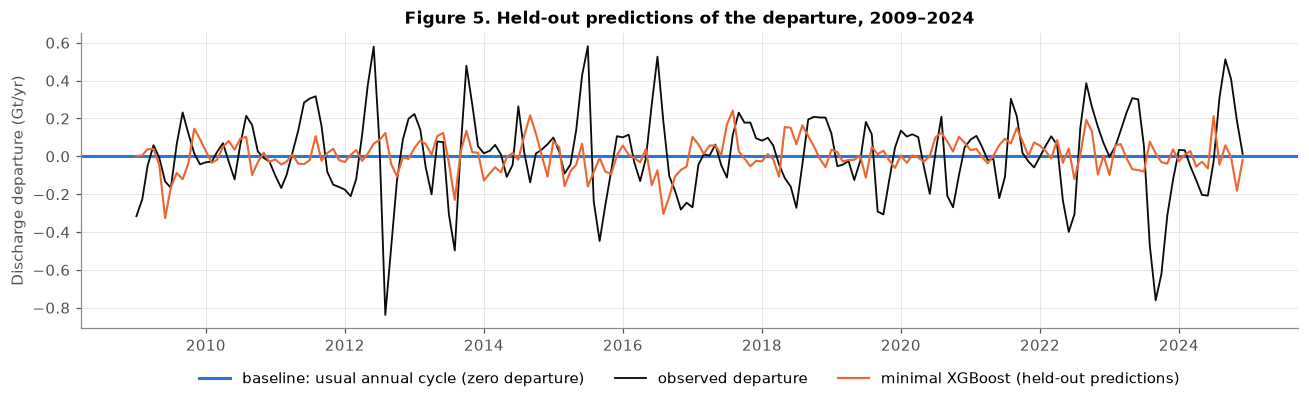

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axhline(0, color=BLUE, lw=2, label="baseline: usual annual cycle (zero departure)")
ax.plot(cv.index, cv["observed"], color=INK, lw=1.2, label="observed departure")
ax.plot(cv.index, cv["xgboost"], color=ORANGE, lw=1.4, label="minimal XGBoost (held-out predictions)")
ax.set(ylabel="Discharge departure (Gt/yr)",
       title="Figure 5. Held-out predictions of the departure, 2009–2024")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
plt.show()

**What the comparison shows**

- **The minimal XGBoost model does slightly *worse* than the baseline.** Its skill is about −0.12 (12% more squared
  error), and it beats the baseline in only 4 of 16 held-out years.
- **Figure 5 shows why.** The model's predictions wiggle with month-to-month weather in the air temperature and runoff
  departures, but those wiggles don't line up with the discharge departures. The large late-summer drops are missed
  entirely.
- **So, at monthly resolution, basin-averaged runoff and air temperature don't explain why individual months depart
  from the usual cycle.** That's a useful result, not a failure: it sets the bar for every model that follows.

### Why a model must beat the baseline before we interpret it

The goal is to explain which drivers matter, using tools like feature importance, SHAP (SHapley Additive
exPlanations) and response curves. But **those tools always give an answer.** They describe what a fitted model
does, not what the glacier does. They will rank inputs and draw curves just as confidently for a model that has
learned nothing but noise.

The only evidence that a model has learned something real is that it **predicts years it has never seen better than
the baseline**, which knows nothing about the drivers. If it can't, then whatever it picked up from the drivers in
the training years doesn't carry over to other years: it's specific to those years, which is to say noise.
Interpreting such a model means explaining noise.

This model is an example. Each of the 16 fold models was trained on slightly different years. Here is the input each
one relied on most:

In [10]:
# Importance = share of a model's total "gain": how much of its error reduction comes from splits on that input
shares = pd.DataFrame(importance).T.fillna(0)
shares = shares.div(shares.sum(axis=1), axis=0)
top = pd.DataFrame({"most important input": shares.idxmax(axis=1), "its share": shares.max(axis=1).round(2)})
print(f"{top['most important input'].nunique()} different inputs come out on top across {len(top)} fold models")
top.rename_axis("held-out year")

6 different inputs come out on top across 16 fold models


,most important input,its share
held-out year,,
2009,runoff_dep_lag1,0.18
2010,air_temp_dep_lag3,0.21
2011,runoff_dep_lag3,0.18
2012,runoff_dep_lag3,0.21
2013,air_temp_dep_lag3,0.19
2014,air_temp_dep_lag3,0.18
2015,air_temp_dep_lag3,0.17
2016,runoff_dep_lag2,0.15
2017,runoff_dep_lag0,0.17


Which input looks "most important" depends on which year happened to be left out. In five folds it's air temperature
three months earlier, and it would be easy to read that as "warm spells affect discharge three months later." But in
the other folds, five other inputs take the top spot. A model that had learned a real relationship would point to the
same inputs whichever year was held out. This one doesn't, because it is fitting noise.

**So the order is:**
1. Beat the baseline: positive skill, and better than the baseline in most held-out years.
2. Only then ask which inputs the model relies on.
3. Check that the answer stays the same across the fold models.

## 5. Next steps

1. **Keep this framework for new inputs.** Same detrending steps, same leave-one-year-out CV, same baseline. A new
   input earns its place only if it beats the baseline: positive skill, and better in most held-out years.
2. **Test seasonal-scale inputs.** Monthly departures are noisy, and a driver may act through a whole season, e.g. a
   warm summer setting up a stronger late-summer slowdown. Candidates are summer-mean air temperature, cumulative
   runoff since melt onset, and melt onset and end dates, used as yearly inputs for the late-summer response.
3. **Move to ice velocity as the target**, as in the project proposal. Its seasonal signal is far stronger than
   discharge's (about half its variance for the fastest-flowing ice, 2015–2025, vs. about 1% for discharge). At 6- or
   12-day resolution it also resolves the timing of speed-ups and slowdowns.
4. **Add ice-front drivers:** mélange break-up timing or rigidity, terminus change (calving), and ocean temperature
   near the terminus. These may explain the large late-summer drops better than melt.
5. **Test the 2013 ice-tongue collapse directly:** compare the seasonal response before and after 2013.
6. **Study the biggest departures as events**, with imagery and terminus records, one year at a time.
7. **Interpret only after beating the baseline**, preferably with models whose structure is readable (e.g. generalized
   additive models) before SHAP or GeoShapley. Check that the explanation is stable across the 16 fold models.